# 01_EDA — NASA C-MAPSS FD001

**Project:** Remaining Useful Life Prediction for Turbofan Engines Using XGBoost and LSTM  
**Dataset:** NASA C-MAPSS FD001

This notebook checks the data before I train any models.

I use it to:
- load the three FD001 files
- check the size of the data
- check missing values and duplicate rows
- look at engine lifetimes
- calculate RUL for the training data
- find constant columns
- look at a few sensor trends
- check simple correlations with RUL


## 1. Imports

I use pandas and NumPy for the data and Matplotlib for the plots.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

## 2. Find the FD001 files

The notebook needs these files:

- `train_FD001.txt`
- `test_FD001.txt`
- `RUL_FD001.txt`

The code first looks in the same folder as the notebook.


In [2]:
def resolve_file(filename):
    local = Path(filename)
    if local.exists():
        return local

    alt = Path("/mnt/data") / filename
    if alt.exists():
        return alt

    raise FileNotFoundError(
        f"{filename} was not found. Put it in the same folder as this notebook."
    )

TRAIN_PATH = resolve_file("train_FD001.txt")
TEST_PATH = resolve_file("test_FD001.txt")
RUL_PATH = resolve_file("RUL_FD001.txt")

print("Training file:", TRAIN_PATH)
print("Test file:    ", TEST_PATH)
print("RUL file:     ", RUL_PATH)

Training file: train_FD001.txt
Test file:     test_FD001.txt
RUL file:      RUL_FD001.txt


## 3. Column names

Each row has:
- engine ID
- cycle number
- 3 operating settings
- 21 sensor readings

That gives 26 columns in total.


In [3]:
columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

print("Number of columns:", len(columns))
print(columns)

Number of columns: 26
['unit', 'cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


## 4. Load the data

The text files do not have column names, so I add the names when I load them.


In [4]:
train = pd.read_csv(TRAIN_PATH, sep=r"\s+", header=None, names=columns)
test = pd.read_csv(TEST_PATH, sep=r"\s+", header=None, names=columns)
test_rul = pd.read_csv(RUL_PATH, sep=r"\s+", header=None, names=["RUL"])

print("Training shape:", train.shape)
print("Test shape:    ", test.shape)
print("RUL shape:     ", test_rul.shape)

Training shape: (20631, 26)
Test shape:     (13096, 26)
RUL shape:      (100, 1)


In [5]:
display(train.head())

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [6]:
display(test.head())

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,21.61,553.90,2388.04,9050.17,1.3,47.20,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,21.61,554.85,2388.01,9054.42,1.3,47.50,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,21.61,554.11,2388.05,9056.96,1.3,47.50,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,21.61,554.07,2388.03,9045.29,1.3,47.28,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,21.61,554.16,2388.01,9044.55,1.3,47.31,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [7]:
display(test_rul.head(10))

,RUL
0,112
1,98
2,69
3,82
4,91
5,93
6,91
7,95
8,111
9,96


## 5. Check the data

Here I check:
- rows and columns
- number of engines
- missing values
- duplicate rows
- data types


In [8]:
summary = pd.DataFrame({
    "Dataset": ["Training", "Test", "Test RUL"],
    "Rows": [len(train), len(test), len(test_rul)],
    "Columns": [train.shape[1], test.shape[1], test_rul.shape[1]],
    "Unique engines": [train["unit"].nunique(), test["unit"].nunique(), np.nan],
    "Missing values": [
        int(train.isna().sum().sum()),
        int(test.isna().sum().sum()),
        int(test_rul.isna().sum().sum())
    ],
    "Duplicate rows": [
        int(train.duplicated().sum()),
        int(test.duplicated().sum()),
        int(test_rul.duplicated().sum())
    ]
})

display(summary)

,Dataset,Rows,Columns,Unique engines,Missing values,Duplicate rows
0,Training,20631,26,100.0,0,0
1,Test,13096,26,100.0,0,0
2,Test RUL,100,1,NaN,0,29


In [9]:
train.dtypes

unit              int64
cycle             int64
op_setting_1    float64
op_setting_2    float64
op_setting_3    float64
sensor_1        float64
sensor_2        float64
sensor_3        float64
sensor_4        float64
sensor_5        float64
sensor_6        float64
sensor_7        float64
sensor_8        float64
sensor_9        float64
sensor_10       float64
sensor_11       float64
sensor_12       float64
sensor_13       float64
sensor_14       float64
sensor_15       float64
sensor_16       float64
sensor_17         int64
sensor_18         int64
sensor_19       float64
sensor_20       float64
sensor_21       float64
dtype: object

## 6. Engine lifetime

The training engines run until failure.

For each engine, its highest cycle number is its lifetime in the training data.


In [10]:
train_lifetime = train.groupby("unit")["cycle"].max()

lifetime_stats = train_lifetime.describe()
display(lifetime_stats.to_frame(name="training_engine_lifetime"))

,training_engine_lifetime
count,100.000000
mean,206.310000
std,46.342749
min,128.000000
25%,177.000000
50%,199.000000
75%,229.250000
max,362.000000


In [11]:
print("Shortest training lifetime:", train_lifetime.min())
print("Longest training lifetime: ", train_lifetime.max())
print("Mean training lifetime:    ", round(train_lifetime.mean(), 2))
print("Median training lifetime:  ", round(train_lifetime.median(), 2))


Shortest training lifetime: 128
Longest training lifetime:  362
Mean training lifetime:     206.31
Median training lifetime:   199.0


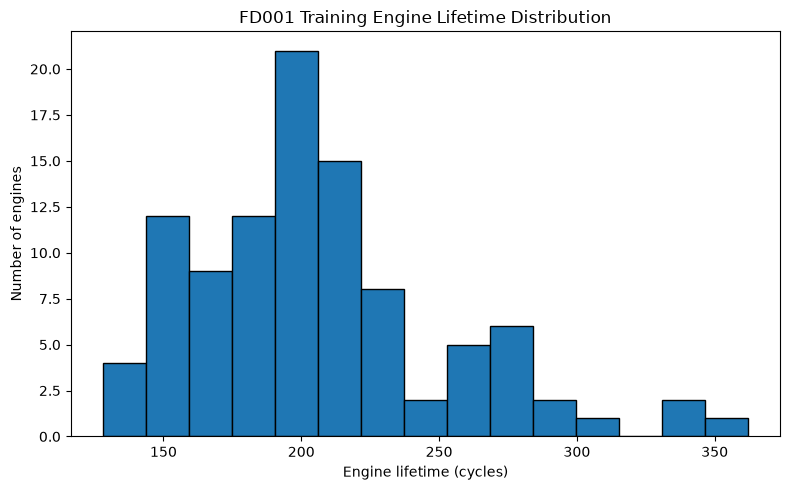

In [12]:
plt.figure(figsize=(8, 5))
plt.hist(train_lifetime.values, bins=15, edgecolor="black")
plt.xlabel("Engine lifetime (cycles)")
plt.ylabel("Number of engines")
plt.title("FD001 Training Engine Lifetime Distribution")
plt.tight_layout()
plt.show()

### What I looked for in the lifetime plot

I checked the shortest and longest lifetimes, the average lifetime, and whether a few engines lasted much longer than the rest.


## 7. Create Remaining Useful Life

For the training data I calculate:

\[
RUL = \text{last cycle of the engine} - \text{current cycle}
\]

So the last row of every training engine should have RUL = 0.


In [13]:
train_eda = train.copy()

max_cycle_per_engine = train_eda.groupby("unit")["cycle"].transform("max")
train_eda["RUL_raw"] = max_cycle_per_engine - train_eda["cycle"]

display(train_eda[["unit", "cycle", "RUL_raw"]].head(10))

,unit,cycle,RUL_raw
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182


In [14]:
# Sanity check: the final observation for every training engine should have RUL = 0
final_rows = train_eda.loc[train_eda.groupby("unit")["cycle"].idxmax()]
print("Unique final-cycle RUL values:", sorted(final_rows["RUL_raw"].unique()))

Unique final-cycle RUL values: [np.int64(0)]


## 8. Check the test RUL values

The test engines stop before failure.

`RUL_FD001.txt` gives the real RUL after the last recorded cycle for each test engine.


In [15]:
display(test_rul.describe().T)

print("Minimum test RUL:", int(test_rul["RUL"].min()))
print("Maximum test RUL:", int(test_rul["RUL"].max()))
print("Mean test RUL:   ", round(test_rul["RUL"].mean(), 2))

,count,mean,std,min,25%,50%,75%,max
RUL,100.0,75.52,41.76497,7.0,32.75,86.0,112.25,145.0


Minimum test RUL: 7
Maximum test RUL: 145
Mean test RUL:    75.52


## 9. Check constant columns

A constant column has the same value in every row.

These columns are not useful for prediction because they do not change.


In [16]:
constant_columns = [
    col for col in columns
    if train[col].nunique(dropna=False) == 1
]

print("Constant columns:")
for col in constant_columns:
    print("-", col)

Constant columns:
- op_setting_3
- sensor_1
- sensor_5
- sensor_10
- sensor_16
- sensor_18
- sensor_19


In [17]:
feature_std = train.drop(columns=["unit", "cycle"]).std().sort_values()
display(feature_std.to_frame(name="standard_deviation"))

,standard_deviation
sensor_1,0.000000e+00
op_setting_3,0.000000e+00
sensor_10,0.000000e+00
sensor_19,0.000000e+00
sensor_18,0.000000e+00
sensor_16,1.387812e-17
sensor_5,1.776400e-15
op_setting_2,2.930621e-04
sensor_6,1.388985e-03
op_setting_1,2.187313e-03


## 10. Look at selected sensors

I plotted sensors 2, 3, 4, 7, 11 and 12 for Engine 1 to see how they changed over time.


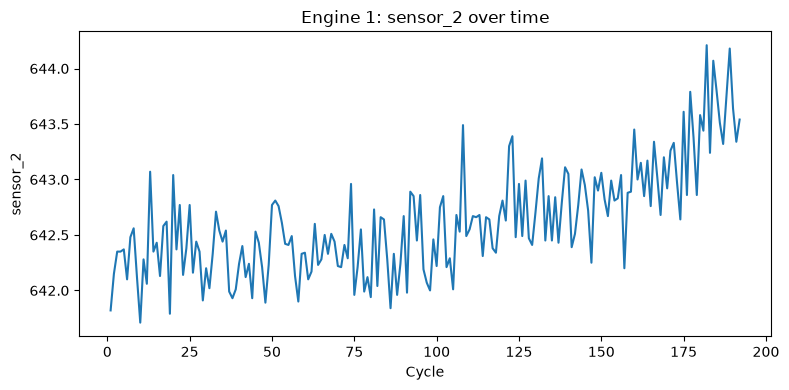

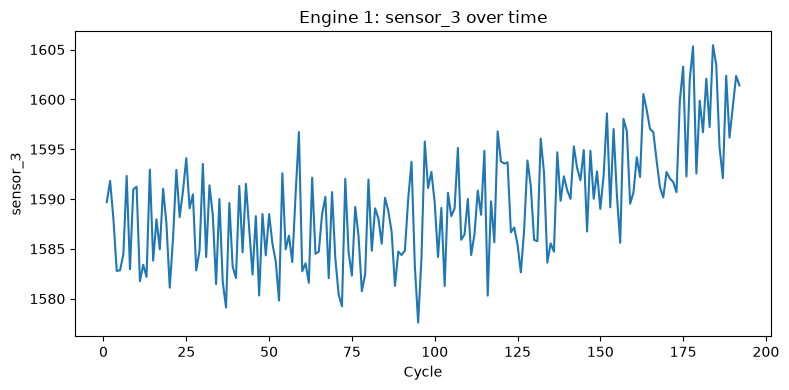

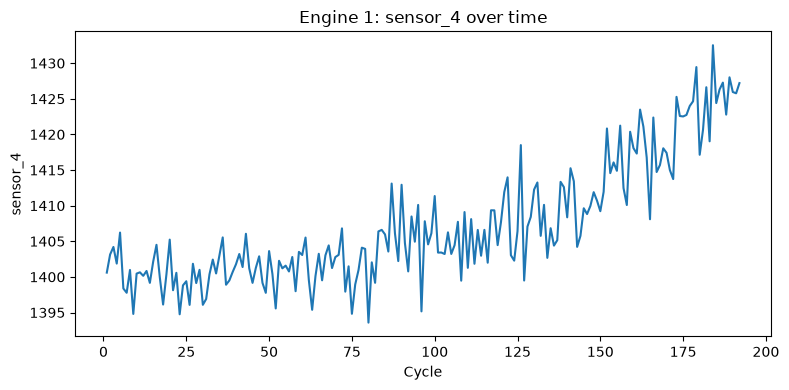

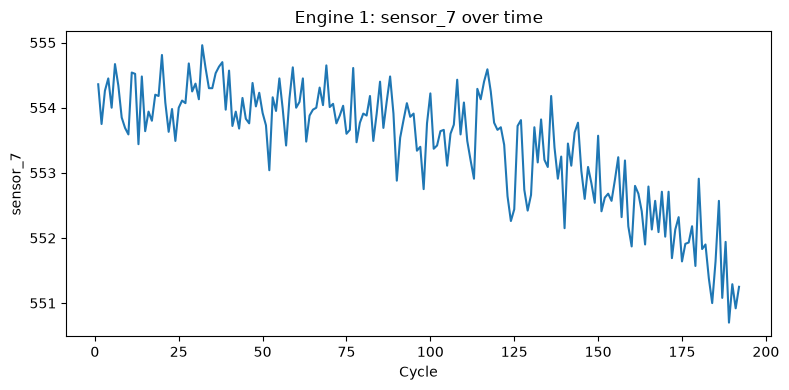

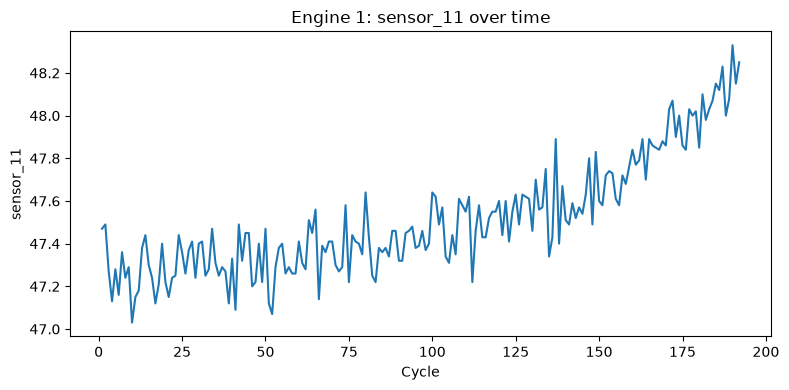

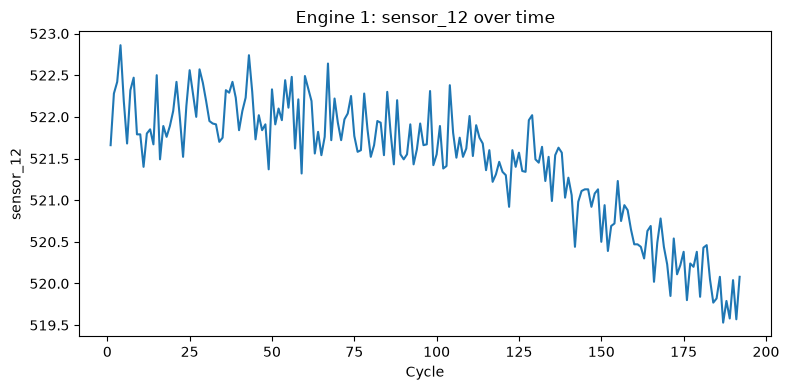

In [18]:
selected_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_11",
    "sensor_12"
]

engine_id = 1
engine_data = train_eda[train_eda["unit"] == engine_id]

for sensor in selected_sensors:
    plt.figure(figsize=(8, 4))
    plt.plot(engine_data["cycle"], engine_data[sensor])
    plt.xlabel("Cycle")
    plt.ylabel(sensor)
    plt.title(f"Engine {engine_id}: {sensor} over time")
    plt.tight_layout()
    plt.show()

## 11. Compare one sensor across engines

This plot checks whether the same sensor shows a similar pattern for several engines.


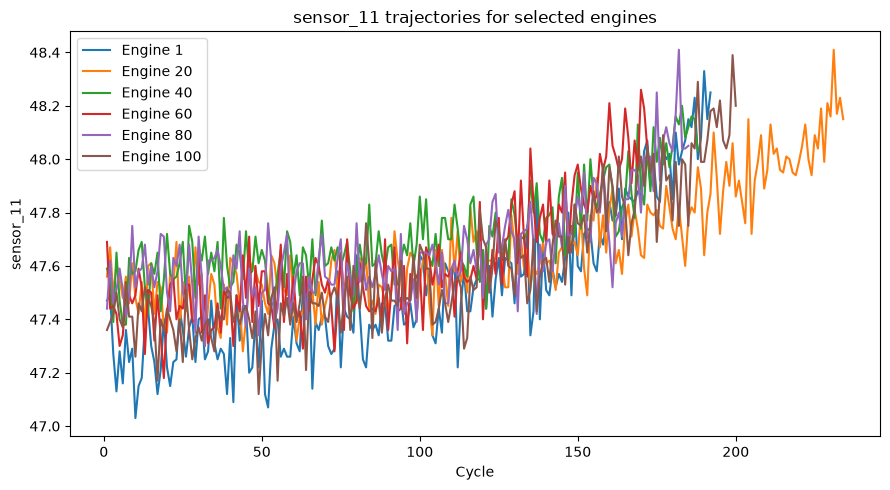

In [19]:
engines_to_plot = [1, 20, 40, 60, 80, 100]
sensor = "sensor_11"

plt.figure(figsize=(9, 5))

for engine_id in engines_to_plot:
    g = train_eda[train_eda["unit"] == engine_id]
    plt.plot(g["cycle"], g[sensor], label=f"Engine {engine_id}")

plt.xlabel("Cycle")
plt.ylabel(sensor)
plt.title(f"{sensor} trajectories for selected engines")
plt.legend()
plt.tight_layout()
plt.show()

## 12. Correlation with RUL

I calculated Pearson correlation between the numeric features and RUL.

This is only a basic check. A feature can still be useful even if its simple correlation is small.


In [20]:
correlations = (
    train_eda
    .drop(columns=["unit"])
    .corr(numeric_only=True)["RUL_raw"]
    .drop("RUL_raw")
    .sort_values()
)

display(correlations.to_frame(name="correlation_with_RUL"))

,correlation_with_RUL
cycle,-0.736241
sensor_11,-0.696228
sensor_4,-0.678948
sensor_15,-0.642667
sensor_2,-0.606484
sensor_17,-0.606154
sensor_3,-0.584520
sensor_8,-0.563968
sensor_13,-0.562569
sensor_9,-0.390102


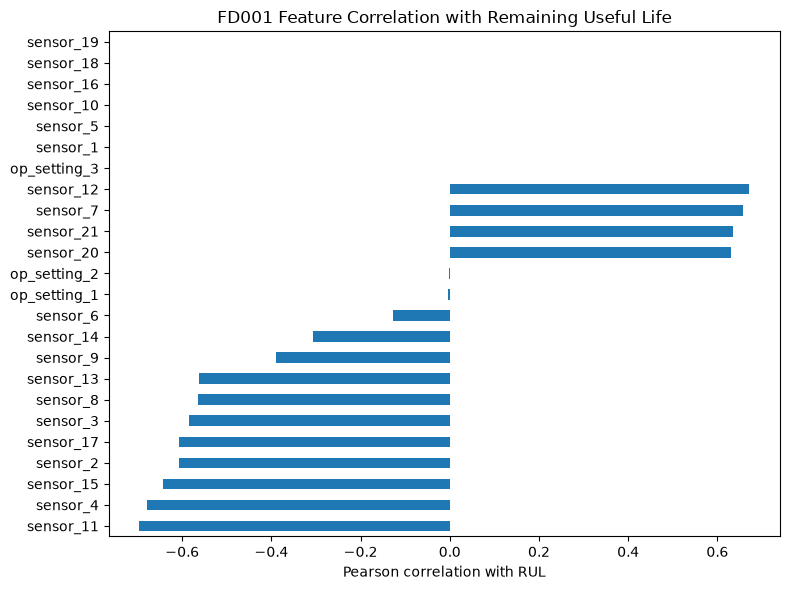

In [21]:
plt.figure(figsize=(8, 6))
correlations.drop(labels=["cycle"], errors="ignore").plot(kind="barh")
plt.xlabel("Pearson correlation with RUL")
plt.title("FD001 Feature Correlation with Remaining Useful Life")
plt.tight_layout()
plt.show()

## 13. Final test cycle

For each test engine I keep its last observed cycle together with the true RUL.

These values are used later when I evaluate the models.


In [22]:
test_last = (
    test.loc[test.groupby("unit")["cycle"].idxmax()]
    .sort_values("unit")
    .reset_index(drop=True)
)

test_last_summary = pd.DataFrame({
    "unit": test_last["unit"],
    "last_observed_cycle": test_last["cycle"],
    "true_remaining_RUL": test_rul["RUL"]
})

display(test_last_summary.head(15))

,unit,last_observed_cycle,true_remaining_RUL
0,1,31,112
1,2,49,98
2,3,126,69
3,4,106,82
4,5,98,91
5,6,105,93
6,7,160,91
7,8,166,95
8,9,55,111
9,10,192,96


## 14. Save the EDA results

The main EDA tables are saved in the `eda_outputs` folder.


In [23]:
OUTPUT_DIR = Path("eda_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

summary.to_csv(OUTPUT_DIR / "dataset_summary.csv", index=False)

pd.DataFrame({
    "unit": train_lifetime.index,
    "lifetime_cycles": train_lifetime.values
}).to_csv(OUTPUT_DIR / "training_engine_lifetimes.csv", index=False)

pd.DataFrame({
    "constant_column": constant_columns
}).to_csv(OUTPUT_DIR / "constant_columns.csv", index=False)

correlations.rename("correlation_with_RUL").to_csv(
    OUTPUT_DIR / "feature_rul_correlations.csv"
)

test_last_summary.to_csv(
    OUTPUT_DIR / "test_engine_final_cycles_and_rul.csv",
    index=False
)

print("Saved EDA files to:", OUTPUT_DIR.resolve())

Saved EDA files to: C:\Users\ak587\Downloads\New folder\eda_outputs


## 15. EDA project log

### Dataset

The training set has **20,631 rows**, **26 columns** and **100 engines**.

The test set has **13,096 rows**, **26 columns** and **100 engines**.

The separate test RUL file has **100 values**, one for each test engine.

### Data quality

I found **no missing values** in the training or test data.

I also found **no duplicate rows** in the training or test sensor data.

The RUL file has repeated numbers, but that is normal because different engines can have the same remaining life.

### Engine lifetime

The shortest training engine lasted **128 cycles** and the longest lasted **362 cycles**.

The mean lifetime was **206.31 cycles** and the median was **199 cycles**.

The middle 50% of engine lifetimes were between **177** and **229.25 cycles**.

### Test RUL

The true test RUL values ranged from **7 to 145 cycles**.

The mean test RUL was **75.52 cycles**.

### Constant columns

I found these constant columns:

- `op_setting_3`
- `sensor_1`
- `sensor_5`
- `sensor_10`
- `sensor_16`
- `sensor_18`
- `sensor_19`

I leave these out of the models because they do not change.

### Sensor patterns

For Engine 1, sensors **2, 3, 4 and 11** generally moved upward over time, while sensors **7 and 12** generally moved downward.

The correlation table also showed some stronger relationships with RUL:

- `sensor_11`: **-0.696**
- `sensor_4`: **-0.679**
- `sensor_12`: **+0.672**
- `sensor_7`: **+0.657**
- `sensor_2`: **-0.606**
- `sensor_3`: **-0.585**

These are simple correlations, so I do not treat them as proof that a sensor causes the change in RUL.

### RUL calculation

For the training data I used:

`RUL = last engine cycle - current cycle`

The check showed that the final row of every training engine had **RUL = 0**.

### Next step

The next notebook trains XGBoost.

I split the data by engine so that rows from the same engine do not appear in both training and validation data.
